# Explore Figure 2(c,d)

Reproduce the online word error rate (WER) and speed values, then inspect the daily counts and timings behind any series.

Open this notebook inside the repository and select **Run All**. Use a Python 3 kernel with Matplotlib and PyYAML. The committed daily table supplies the inputs, so the notebook runs without raw recordings, model weights, or a GPU.

[Daily data](results/20261124_repository_migration/figure2cd_daily.csv) · [Methods, source cohorts, and corrections](docs/20261124_evaluation_protocol/figure2cd.md)

In [1]:
import csv
import sys
from datetime import date
from io import BytesIO
from pathlib import Path

import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import yaml
from IPython.display import Image, Markdown, display

working_dir = Path.cwd().resolve()
repo_root = next(
    (parent for parent in (working_dir, *working_dir.parents)
     if (parent / "figures" / "reproduction_benchmark.yaml").is_file()
     and (parent / "figures/results/20261124_repository_migration/figure2cd_daily.csv").is_file()),
    None,
)
if repo_root is None:
    raise FileNotFoundError("Open this notebook from the repository or its figures directory.")
if str(repo_root / 'figures' / 'code') not in sys.path:
    sys.path.insert(0, str(repo_root / 'figures' / 'code'))

from build_figure2_data import apply_daily_metrics, read_daily

benchmark_path = repo_root / "figures" / "reproduction_benchmark.yaml"
benchmark = yaml.safe_load(benchmark_path.read_text(encoding="utf-8"))
csv_path = repo_root / benchmark["panel_cd_daily_csv"]
apply_daily_metrics(benchmark, benchmark_path)

panel_rows = benchmark["panel_cd_online_wer_speed"]
series_rows = {row["daily_series"]: row for row in panel_rows if "daily_series" in row}
daily_rates = read_daily(csv_path)
with csv_path.open(encoding="utf-8", newline="") as stream:
    daily_counts = list(csv.DictReader(stream))

print(f"Loaded {len(daily_counts)} daily records for {len(daily_rates)} series.")

Loaded 55 daily records for 10 series.


## Daily CSV columns

Each row represents one participant on one recording day. The file stores both the daily rates and the counts and time used to calculate them.

| Column | Meaning |
|---|---|
| `series` | Study and participant ID. For example, `jude26b_t17` is participant T17 in Jude 2026b. |
| `day` | Calendar recording date in YYYY-MM-DD format. |
| `released_trials` | Number of released trials within the selected evaluation conditions on that day. |
| `wer_trials` | Number of trials scored for word error rate (WER), with a usable reference and a recoverable decoder output record. |
| `word_errors` | Total word insertions, deletions, and substitutions across the WER trials. |
| `reference_words` | Total reference words across the WER trials. |
| `speed_trials` | Number of scored trials with a valid duration that contribute to the speed calculation. |
| `speed_count` | Total reference words or characters in the timed trials. |
| `speed_unit` | Unit of `speed_count`. Speech uses `words`. Handwriting and typing use `characters`, including spaces, with five characters per word equivalent. |
| `seconds` | Total duration in seconds across the timed trials. |
| `source` | Public file or evaluation block group from which the row was calculated. |
| `wer_pct` | Daily WER as a percentage. Multiply the total word errors by 100 and divide by the reference word count. |
| `speed_wpm` | Daily speed in words per minute. Divide the reference word count (or the character count divided by five) by total trial minutes. |

Empty speed fields indicate that the row has no speed measurement. For Jude 2026b on **2024-04-02**, 11 trials produced 59 word errors over 64 reference words, giving **92.19% WER**. The 64 reference words over 125.562 seconds give **30.6 WPM**.

## Read the panel values

- **Daily WER (%)** is 100 × total word edits ÷ total reference words. Word edits include insertions, deletions, and substitutions.
- **Daily speed (WPM)** is the reference word count ÷ total trial minutes. Handwriting and typing use one word equivalent per five reference characters.
- **Mean ± sample SD** gives each day equal weight. A single day has no SD. The Wairagkar row shows the paper's listener transcription median from 90 sampled synthesized-speech trials.

In [2]:
def format_estimate(value, sd):
    """Format an estimate at the precision used in Figure 2."""
    if value is None:
        return "—"
    return f"{value:.1f}" if sd is None else f"{value:.1f} ± {sd:.1f}"


def show_table(columns, rows):
    """Display a Markdown table with the given columns and rows."""
    lines = ["| " + " | ".join(columns) + " |",
             "| " + " | ".join(["---"] * len(columns)) + " |"]
    lines.extend("| " + " | ".join(str(value) for value in row) + " |" for row in rows)
    display(Markdown("\n".join(lines)))


overview = []
for row in panel_rows:
    series_id = row.get("daily_series")
    wer = format_estimate(row["wer_mean"], row["wer_sd"])
    speed = format_estimate(row["speed_wpm_mean"], row["speed_wpm_sd"])
    if series_id:
        wer_days = f"{len(row['wer_dates'])} / {row['released_days']}"
        speed_days = (
            f"{len(row['speed_wpm_dates'])} / {row['released_days']}"
            if row["speed_wpm_dates"] else "—"
        )
    else:
        wer = f"{wer} (listener median)"
        wer_days = "—"
        speed_days = "—"
    overview.append((row["label"], row["vocab_tag"], series_id or "—",
                     wer, wer_days, speed, speed_days))

show_table(
    ("Study and participant", "Vocabulary", "Series ID", "WER (%)",
     "WER days (used / released)", "Speed (WPM)", "Speed days (used / released)"),
    overview,
)

| Study and participant | Vocabulary | Series ID | WER (%) | WER days (used / released) | Speed (WPM) | Speed days (used / released) |
| --- | --- | --- | --- | --- | --- | --- |
| Willett et al., 2021 (T5) | open | willett21_t5 | 23.9 ± 8.4 | 5 / 10 | 14.3 ± 1.8 | 5 / 10 |
| Willett et al., 2023 (T12) | 125k | willett23_t12 | 23.8 ± 1.8 | 5 / 24 | 65.9 ± 0.9 | 5 / 24 |
| Fan et al., 2023 (T5) | 130k | fan23_t5 | 4.0 ± 1.2 | 10 / 21 | 14.4 ± 1.6 | 10 / 21 |
| Card et al., 2024 (T15) | 125k | card24_t15 | 4.9 ± 3.3 | 14 / 45 | 32.6 ± 2.6 | 14 / 45 |
| Wairagkar et al., 2025 (T15) | open | — | 43.8 (listener median) | — | — | — |
| Kunz et al., 2025 (T12) | 50-w | kunz25_t12 | 22.9 | 1 / 1 | — | — |
| Kunz et al., 2025 (T15) | 125k | kunz25_t15 | 43.3 ± 23.8 | 2 / 3 | — | — |
| Kunz et al., 2025 (T16) | 125k | kunz25_t16 | 44.4 | 1 / 2 | — | — |
| Jude et al., 2026a (T17) | 125k | jude26a_t17 | 10.5 ± 3.1 | 6 / 8 | 5.7 ± 1.7 | 6 / 8 |
| Jude et al., 2026a (T18) | 125k | jude26a_t18 | 3.5 ± 0.6 | 7 / 9 | 13.0 ± 4.2 | 7 / 9 |
| Jude et al., 2026b (T17) | 125k | jude26b_t17 | 66.5 ± 18.1 | 4 / 13 | 31.9 ± 1.4 | 4 / 13 |

## Inspect one series

Copy a **Series ID** from the table into the next cell, then rerun that cell and the cells below. The default is Jude 2026b, whose WER and speed use the same four evaluation days. Try **kunz25_t12** for a single-day result with WER only.

In [3]:
selected_series = "jude26b_t17"

if selected_series not in series_rows:
    raise ValueError(f"Choose one of these series IDs: {', '.join(series_rows)}")

selection = series_rows[selected_series]
selected_counts = [row for row in daily_counts if row["series"] == selected_series]
selected_rates = daily_rates[selected_series]
print(selection["label"])

Jude et al., 2026b (T17)


In [4]:
detail = []
for row in selected_counts:
    wer, speed, speed_unit = selected_rates[row["day"]]
    word_counts = (
        f"{row['word_errors']} / {row['reference_words']}"
        if row["wer_trials"] else "—"
    )
    speed_input = (
        f"{row['speed_count']} {speed_unit} / {float(row['seconds']):.1f} s"
        if row["speed_trials"] else "—"
    )
    detail.append((
        row["day"], row["wer_trials"] or "—", word_counts,
        format_estimate(wer, None), row["speed_trials"] or "—",
        speed_input, format_estimate(speed, None),
    ))

show_table(
    ("Recording date", "WER trials", "Word edits / reference words", "WER (%)",
     "Timed trials", "Reference count / time", "Speed (WPM)"),
    detail,
)

| Recording date | WER trials | Word edits / reference words | WER (%) | Timed trials | Reference count / time | Speed (WPM) |
| --- | --- | --- | --- | --- | --- | --- |
| 2024-04-02 | 11 | 59 / 64 | 92.2 | 11 | 64 words / 125.6 s | 30.6 |
| 2024-05-07 | 200 | 625 / 1251 | 50.0 | 200 | 1251 words / 2325.3 s | 32.3 |
| 2024-05-14 | 178 | 655 / 1097 | 59.7 | 178 | 1097 words / 2111.7 s | 31.2 |
| 2024-05-28 | 80 | 312 / 487 | 64.1 | 80 | 487 words / 865.9 s | 33.7 |

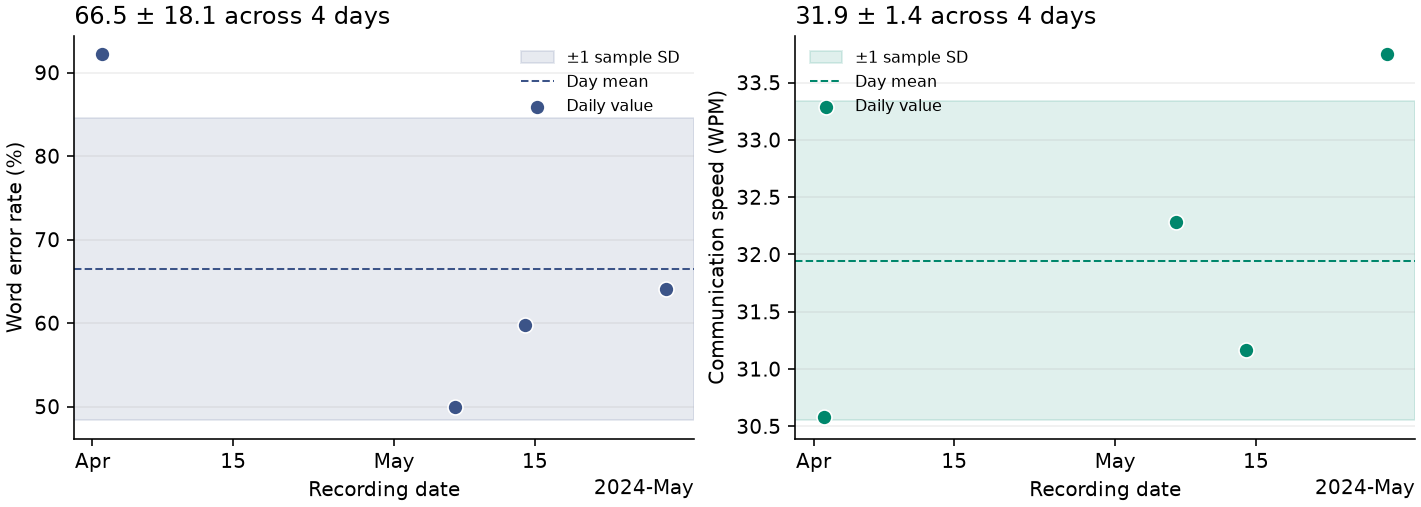

In [5]:
metrics = [
    (0, "wer", "Word error rate (%)", "#3C5488"),
    (1, "speed_wpm", "Communication speed (WPM)", "#00876C"),
]
available_metrics = [metric for metric in metrics if selection[f"{metric[1]}_dates"]]
fig, axes = plt.subplots(
    1, len(available_metrics), figsize=(4.9 * len(available_metrics), 3.5),
    layout="constrained", squeeze=False,
)

for ax, (index, metric, ylabel, color) in zip(axes[0], available_metrics, strict=True):
    days = [date.fromisoformat(day) for day in selection[f"{metric}_dates"]]
    values = [selected_rates[day.isoformat()][index] for day in days]
    mean, sd = selection[f"{metric}_mean"], selection[f"{metric}_sd"]
    if sd is not None:
        ax.axhspan(mean - sd, mean + sd, color=color, alpha=0.12, label="±1 sample SD")
        ax.axhline(mean, color=color, linestyle="--", linewidth=1, label="Day mean")
    ax.scatter(days, values, color=color, edgecolors="white", linewidths=0.8,
               s=55, zorder=3, label="Daily value")
    ax.set(xlabel="Recording date", ylabel=ylabel)
    ax.set_title(f"{format_estimate(mean, sd)} across {len(days)} "
                 f"{'day' if len(days) == 1 else 'days'}", loc="left")
    if len(days) == 1:
        ax.set_xticks(days, [days[0].isoformat()])
    else:
        locator = mdates.AutoDateLocator(minticks=3, maxticks=7)
        ax.xaxis.set_major_locator(locator)
        ax.xaxis.set_major_formatter(mdates.ConciseDateFormatter(locator))
    ax.grid(axis="y", alpha=0.22)
    ax.spines[["top", "right"]].set_visible(False)
    ax.legend(frameon=False, fontsize=8)

with BytesIO() as png:
    fig.savefig(png, format="png", dpi=145)
    display(Image(data=png.getvalue()))
plt.close(fig)

## Check the two WER denominators

The first calculation below combines the word counts **within one day**. The second comparison shows what happens **across days** if you pool the word counts again. Pooling across days gives dates with more reference words more weight. Figure 2 averages the daily rates so that every included day has the same weight.

In [6]:
scored_days = [row for row in selected_counts if row["wer_trials"]]
if scored_days:
    first = scored_days[0]
    edits, words = int(first["word_errors"]), int(first["reference_words"])
    pooled_edits = sum(int(row["word_errors"]) for row in scored_days)
    pooled_words = sum(int(row["reference_words"]) for row in scored_days)
    print(f"{first['day']}  100 × {edits} / {words} = {100 * edits / words:.2f}% WER")
    print(f"Equal-day mean shown in the figure: {selection['wer_mean']:.2f}%")
    print(f"All words pooled across days:       {100 * pooled_edits / pooled_words:.2f}%")
else:
    print("This series has no daily WER counts.")

2024-04-02  100 × 59 / 64 = 92.19% WER
Equal-day mean shown in the figure: 66.48%
All words pooled across days:       56.95%


## Willett 2023 coverage in Figures 2c and 3a

The archived pairing table matches online and offline records by session, block, and unique reference.

In [7]:
bundle = repo_root / "figures/results/20261124_repository_migration"
online = [r for r in daily_counts if r["series"] == "willett23_t12"]
with (bundle / "session_per_vs_wer.json").open(encoding="utf-8") as stream:
    offline = __import__("json").load(stream)["Willett 2023 (T12)"]["sessions"]
with (bundle / "figure2cd_paired_trials.csv").open(encoding="utf-8", newline="") as stream:
    matched = [r for r in csv.DictReader(stream) if r["series"] == "willett23_t12"]
coverage = (len(online), sum(int(r["wer_trials"]) for r in online),
            len(offline), sum(r["n"] for r in offline), len(matched))
print(f"Figure 2c: {coverage[0]} days, {coverage[1]} online trials")
print(f"Figure 3a: {coverage[2]} days, {coverage[3]} offline evaluation trials")
print(f"Matched trials: {coverage[4]}")
assert coverage == (5, 400, 24, 880, 200)

Figure 2c: 5 days, 400 online trials
Figure 3a: 24 days, 880 offline evaluation trials
Matched trials: 200
